
# Adaptive image decomposition with an external potential

This study tests the lens-independent decomposer on point-mass (PM) and singular
isothermal-sphere (SIS) lenses in an external convergence and shear field.  The
tested settings contain one, two, or four ordinary geometric images and are
chosen away from caustic crossings.

For image positions $\boldsymbol{x}_i$, the external potential is

$$
\psi_{\rm ext}(\boldsymbol{x})=
\frac{\kappa}{2}|\boldsymbol{x}|^2+
\frac{\gamma_1}{2}(x_1^2-x_2^2)+\gamma_2x_1x_2.
$$

The decomposer represents the amplification as

$$
F_{\rm fit}(w)=\sum_iG_i(w)\exp\!\left[iw\Delta\tau_i-i\pi n_i/2\right],
$$

where $n_i$ is the Morse index.  Two fits are compared.  The geometric fit uses
$G_i\rightarrow\sqrt{|\mu_i|}$ as its high-frequency baseline.  The BGO fit uses

$$
G_i^{\rm base}(w)=\sqrt{|\mu_i|}\left[1+W(w)
\sum_{k=1}^{2}B_{ik}\left(\frac{i}{w}\right)^k\right],
$$

with the decomposer's smooth, data-selected turn-on $W(w)$.  In both fits the
spline deviation is defined relative to the geometric limit and falls as
$(1+w)^{-1}$.  The common knot set is adapted until

$$
\frac{\|F_{\rm fit}-F_{\rm true}\|_2}{\|F_{\rm true}\|_2}\leq
\epsilon_{\rm GLoW}.
$$

Here $\epsilon_{\rm GLoW}$ is measured separately for each lens as the relative
$L^2$ difference between consecutive GLoW contour resolutions.  A reference is
used only if this uncertainty is at most one percent and the higher-resolution
calculation of the complete frequency array takes at most one second.


In [1]:

import os
for variable in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS',
                 'NUMEXPR_NUM_THREADS'):
    os.environ[variable] = '1'
os.environ.setdefault('MPLCONFIGDIR', '/tmp/external_potential_matplotlib')

import shutil
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from cycler import cycler
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
if ROOT.name == 'decomposition':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT/'bgo'))

from bgo.adaptive_reference import adaptive_glow_reference
from decomposition.decomposer import decompose
from expansion import _image_data

FIGURE_DIR = ROOT/'decomposition'/'external_potential_figures'
FIGURE_DIR.mkdir(exist_ok=True)

my_colors = ['navy', 'coral', 'c', 'crimson', 'springgreen', 'gold',
             'dodgerblue', 'hotpink', 'forestgreen', 'moccasin', 'darkred', 'teal']
use_tex = all(shutil.which(name) for name in ('latex', 'dvipng'))
rc_params = {'axes.labelsize': 14, 'axes.titlesize': 14, 'legend.fontsize': 11,
             'xtick.labelsize': 12, 'ytick.labelsize': 12,
             'text.usetex': use_tex, 'text.latex.preamble': r'\usepackage{txfonts}',
             'font.size': 14, 'font.family': 'serif',
             'font.serif': 'times' if use_tex else 'DejaVu Serif',
             'mathtext.default': 'sf', 'lines.markeredgewidth': 1,
             'lines.linewidth': 2, 'axes.prop_cycle': cycler(color=my_colors)}
rcParams.update(rc_params)
if not use_tex:
    print('LaTeX rendering is disabled. Install latex and dvipng to use the requested plot fonts.')



## Regimes, GLoW convergence, and geometric data

Every case uses lens strength one, convergence $\kappa=0.1$, and principal-axis
shear $\gamma=0.2$.  The source positions sample each available image-count
regime.  GLoW rotates the source onto its scalar source axis and rotates the shear
as a spin-two field.  This is only a coordinate change.

The signed magnification is $\mu_i=1/\det H_i$, where $H_i$ is the Hessian of the
Fermat potential.  Arrival times are shifted by the earliest image, which changes
only the common phase convention.  GLoW's regularized Fourier transform already
uses the earliest image as its phase origin.


In [2]:

W = np.geomspace(0.1, 20, 121)
KAPPA, GAMMA = 0.1, 0.2
CASE_SETTINGS = [
    ('PM / field, two images', 'PM', np.array([0.60, 0.12])),
    ('PM / field, four images', 'PM', np.array([0.04, 0.06])),
    ('SIS / field, one image', 'SIS', np.array([2.00, 0.20])),
    ('SIS / field, two images', 'SIS', np.array([0.60, 0.12])),
    ('SIS / field, four images', 'SIS', np.array([0.04, 0.06])),
]

def geometric_data(model, source):
    images = _image_data(model, source, 1.0, (GAMMA, 0.0), order=2,
                         convergence=KAPPA)
    arrival_times = np.array([image['tau'] for image in images])
    delays = arrival_times-arrival_times.min()
    magnifications = np.array([1/image['determinant'] for image in images])
    morse_shifts = -0.5*np.pi*np.array([image['morse'] for image in images])
    bgo = np.array([image['coefficients'][1:3] for image in images])
    return delays, magnifications, morse_shifts, bgo

cases = []
for name, model, source in CASE_SETTINGS:
    wave, spread, glow = adaptive_glow_reference(
        model, source, 1.0, GAMMA, KAPPA, W,
        relative_l2_limit=0.01, seconds_per_array=1.0)
    delays, magnifications, morse_shifts, bgo = geometric_data(model, source)
    phase = np.exp(1j*(delays[:, None]*W[None, :]+morse_shifts[:, None]))
    geometric = np.sum(np.sqrt(abs(magnifications))[:, None]*phase, axis=0)
    cases.append(dict(name=name, model=model, source=source, w=W, wave=wave,
                      spread=spread, glow=glow, delays=delays,
                      magnifications=magnifications, morse_shifts=morse_shifts,
                      bgo=bgo, geometric=geometric))

lines = ['| Lens | Source | Images | Contour samples | Array time (s) | Relative L2 uncertainty |',
         '|---|---:|---:|---:|---:|---:|']
for case in cases:
    level = case['glow']['levels'][-1]
    lines.append(f"| {case['name']} | {tuple(case['source'])} | {len(case['delays'])} | "
                 f"{level['settings']['Nt']} | {case['glow']['array_evaluation_seconds']:.3f} | "
                 f"{case['glow']['relative_l2_uncertainty']:.3e} |")
display(Markdown('\n'.join(lines)))


| Lens | Source | Images | Contour samples | Array time (s) | Relative L2 uncertainty |
|---|---:|---:|---:|---:|---:|
| PM / field, two images | (0.6, 0.12) | 2 | 4500 | 0.450 | 3.063e-04 |
| PM / field, four images | (0.04, 0.06) | 4 | 4500 | 0.577 | 1.259e-04 |
| SIS / field, one image | (2.0, 0.2) | 1 | 4500 | 0.280 | 4.595e-04 |
| SIS / field, two images | (0.6, 0.12) | 2 | 4500 | 0.296 | 2.860e-04 |
| SIS / field, four images | (0.04, 0.06) | 4 | 4500 | 0.402 | 1.804e-04 |


## Adaptive fits

Each fit uses its measured $\epsilon_{\rm GLoW}$ as the discrete relative $L^2$
limit.  Knot locations are common to all factors in a fit.  The two-image PM
case uses no ghost.  The four-image PM case searches for up to one ghost.  SIS
searches for one ghost associated with diffraction from the conical centre,
and the four-image SIS case searches for up to two ghosts.  Candidates below
the Fourier support threshold are discarded.


In [3]:

results = []

for case in cases:
    l2_limit = case['glow']['relative_l2_uncertainty']
    ghost_count = 1 if case['model'] == 'SIS' else 0
    if len(case['delays']) == 4:
        ghost_count += 1
    common = dict(w=case['w'], wave=case['wave'], delays=case['delays'],
                  magnifications=case['magnifications'],
                  morse_shifts=case['morse_shifts'], l2_limit=l2_limit,
                  ghost_count=ghost_count,
                  min_knots=3, max_initial_knots=20, max_knots=120,
                  factor_scale_limit=10.0, optimizer_maxiter=0,
                  fit_weight=0.01, amplitude_weight=0.02,
                  curvature_weight=0.02)
    start = time.perf_counter()
    geometric_fit = decompose(**common)
    geometric_seconds = time.perf_counter()-start
    start = time.perf_counter()
    bgo_fit = decompose(**common, bgo_coefficients=case['bgo'])
    bgo_seconds = time.perf_counter()-start
    case['geometric_fit'] = geometric_fit
    case['bgo_fit'] = bgo_fit

    for label, fit, seconds in [('geometric baseline', geometric_fit, geometric_seconds),
                                ('two BGO orders', bgo_fit, bgo_seconds)]:
        residual = fit.amplification(case['w'])-case['wave']
        knot_factor_scale = np.max(abs(fit.components(10**fit.knots)))
        geometric_scale = np.max(np.sqrt(abs(case['magnifications'])))
        results.append(dict(case=case['name'], lens=case['model'],
                            images=len(case['delays']), method=label,
                            ghosts=fit.ghost_count,
                            ghost_delays=fit.ghost_delays,
                            ghost_support=(None if fit.ghost_spectral_support is None else
                                           np.min(fit.ghost_spectral_support, axis=1)),
                            ghost_residual_strength=fit.ghost_residual_spectral_strength,
                            ghost_prefit_l2=fit.ghost_prefit_relative_l2,
                            knots=len(fit.knots), relative_l2=fit.relative_l2,
                            max_error=np.max(abs(residual)),
                            bgo_start=fit.bgo_start, seconds=seconds,
                            initial_knots=fit.history[0][0], fits_tried=len(fit.history),
                            factor_scale_ratio=knot_factor_scale/geometric_scale,
                            glow_uncertainty=l2_limit,
                            glow_seconds=case['glow']['array_evaluation_seconds']))
    print(f"{case['name']}: geometric {len(geometric_fit.knots)} knots, "
          f"{geometric_seconds:.2f} s; BGO {len(bgo_fit.knots)} knots, "
          f"{bgo_seconds:.2f} s")


PM / field, two images: geometric 8 knots, 0.02 s; BGO 8 knots, 0.02 s


PM / field, four images: geometric 55 knots, 0.80 s; BGO 55 knots, 0.83 s


SIS / field, one image: geometric 6 knots, 0.16 s; BGO 6 knots, 0.18 s
SIS / field, two images: geometric 8 knots, 0.03 s; BGO 8 knots, 0.03 s


SIS / field, four images: geometric 46 knots, 0.65 s; BGO 46 knots, 0.71 s


In [4]:

lines = ['| Lens and external field | Images | Ghosts | Baseline | Initial knots | Final knots | '
         'Fits tried | Fit time (s) | Relative L2 | GLoW uncertainty | Maximum complex error | '
         r'$\max|G_i|/\max\sqrt{|\mu_i|}$ | Ghost delays | Residual Fourier strength | '
         'Minimum shared Fourier support | BGO start |',
         '|---|---:|---:|---|---:|---:|---:|---:|---:|---:|---:|---|---|---|---:|']
for row in results:
    start = '--' if row['bgo_start'] is None else f"{row['bgo_start']:.3g}"
    ghost_delays = ', '.join(f"{value:.3g}" for value in row['ghost_delays']) or '--'
    ghost_support = ('--' if row['ghost_support'] is None or
                     len(row['ghost_support']) == 0 else
                     ', '.join(f"{value:.2f}" for value in row['ghost_support']))
    ghost_residual_strength = ('--' if row['ghost_residual_strength'] is None or
                               len(row['ghost_residual_strength']) == 0 else
                               ', '.join(f"{value:.2f}" for value in
                                         row['ghost_residual_strength']))
    lines.append(f"| {row['case']} | {row['images']} | {row['ghosts']} | {row['method']} | "
                 f"{row['initial_knots']} | {row['knots']} | {row['fits_tried']} | "
                 f"{row['seconds']:.2f} | {row['relative_l2']:.3e} | "
                 f"{row['glow_uncertainty']:.3e} | "
                 f"{row['max_error']:.3e} | {row['factor_scale_ratio']:.3e} | "
                 f"{ghost_delays} | {ghost_residual_strength} | {ghost_support} | {start} |")
display(Markdown('\n'.join(lines)))


| Lens and external field | Images | Ghosts | Baseline | Initial knots | Final knots | Fits tried | Fit time (s) | Relative L2 | GLoW uncertainty | Maximum complex error | $\max|G_i|/\max\sqrt{|\mu_i|}$ | Ghost delays | Residual Fourier strength | Minimum shared Fourier support | BGO start |
|---|---:|---:|---|---:|---:|---:|---:|---:|---:|---:|---|---|---|---:|
| PM / field, two images | 2 | 0 | geometric baseline | 5 | 8 | 4 | 0.02 | 3.032e-04 | 3.063e-04 | 1.115e-03 | 1.144e+00 | -- | -- | -- | -- |
| PM / field, two images | 2 | 0 | two BGO orders | 5 | 8 | 4 | 0.02 | 3.032e-04 | 3.063e-04 | 1.115e-03 | 1.144e+00 | -- | -- | -- | 20 |
| PM / field, four images | 4 | 0 | geometric baseline | 3 | 55 | 53 | 0.80 | 6.296e-05 | 1.259e-04 | 5.849e-04 | 5.247e+00 | -- | -- | -- | -- |
| PM / field, four images | 4 | 0 | two BGO orders | 3 | 55 | 53 | 0.83 | 6.296e-05 | 1.259e-04 | 5.849e-04 | 5.247e+00 | -- | -- | -- | 20 |
| SIS / field, one image | 1 | 1 | geometric baseline | 18 | 6 | 14 | 0.16 | 4.474e-04 | 4.595e-04 | 2.131e-03 | 1.001e+00 | 6.42 | 1.00 | 0.16 | -- |
| SIS / field, one image | 1 | 1 | two BGO orders | 18 | 6 | 14 | 0.18 | 4.474e-04 | 4.595e-04 | 2.133e-03 | 1.001e+00 | 6.42 | 1.00 | 0.15 | 14.7 |
| SIS / field, two images | 2 | 1 | geometric baseline | 6 | 8 | 3 | 0.03 | 2.734e-04 | 2.860e-04 | 1.384e-03 | 7.958e+00 | 1.34 | 0.11 | 0.01 | -- |
| SIS / field, two images | 2 | 1 | two BGO orders | 6 | 8 | 3 | 0.03 | 2.734e-04 | 2.860e-04 | 1.384e-03 | 7.958e+00 | 1.34 | 0.11 | 0.01 | 20 |
| SIS / field, four images | 4 | 1 | geometric baseline | 3 | 46 | 44 | 0.65 | 9.022e-05 | 1.804e-04 | 1.287e-03 | 7.502e+00 | 0.906 | 0.67 | 0.02 | -- |
| SIS / field, four images | 4 | 1 | two BGO orders | 3 | 46 | 44 | 0.71 | 9.022e-05 | 1.804e-04 | 1.287e-03 | 7.502e+00 | 0.906 | 0.67 | 0.02 | 20 |


## Fourier diagnosis of the four-image ghosts

The dashed curves are the normalized Fourier amplitudes of
$(1+w)[G_i-G_i^{\rm base}]\exp[i(wt_i+\phi_i)]$ from the 1% no-ghost prefit.
They test whether a candidate delay is shared by the physical image factors.
The black curve is the normalized Fourier amplitude of the remaining prefit
residual after removing the same $1/(1+w)$ envelope.  Its strongest peaks set
the initial ghost delays.  Red dotted lines mark ordinary image delays and
blue lines mark the selected ghost delays.


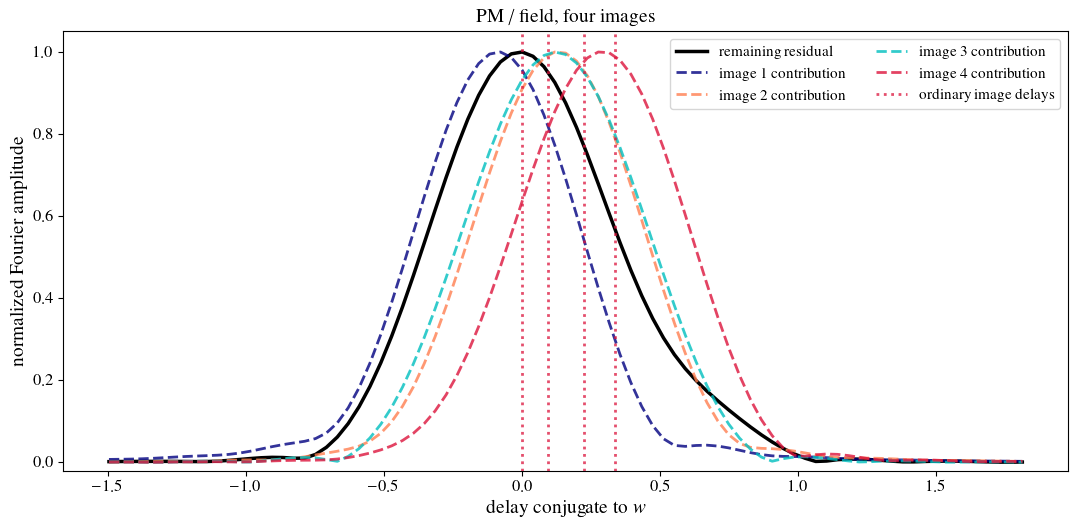

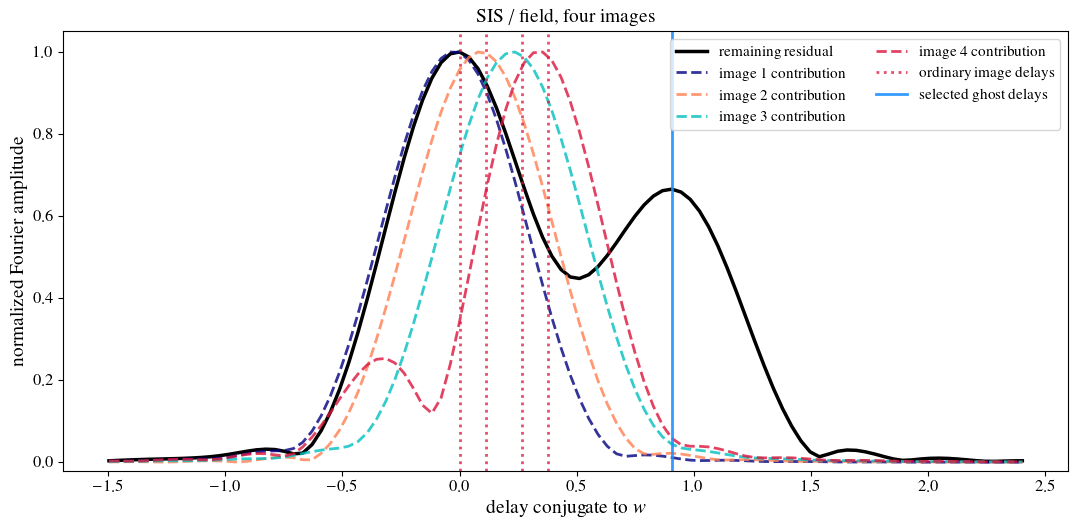

In [5]:

for case in cases:
    if len(case['delays']) != 4:
        continue
    fit = case['geometric_fit']
    delay_axis = fit.ghost_spectrum_delays
    residual_spectrum = fit.ghost_residual_spectrum
    component_spectra = fit.ghost_component_spectra
    all_delays = np.r_[case['delays'], fit.ghost_delays]
    padding = max(1.5, 3*fit.ghost_delay_resolution)
    shown = ((delay_axis >= all_delays.min()-padding)
             & (delay_axis <= all_delays.max()+padding))

    fig, ax = plt.subplots(figsize=(11, 5.5))
    ax.plot(delay_axis[shown], residual_spectrum[shown], color='black',
            label='remaining residual', linewidth=2.5)
    for image_index, spectrum in enumerate(component_spectra):
        ax.plot(delay_axis[shown], spectrum[shown], linestyle='--', alpha=0.8,
                label=fr'image {image_index+1} contribution')
    for image_index, delay in enumerate(case['delays']):
        ax.axvline(delay, color='crimson', linestyle=':', alpha=0.75,
                   label='ordinary image delays' if image_index == 0 else None)
    for ghost_index, delay in enumerate(fit.ghost_delays):
        ax.axvline(delay, color='dodgerblue', alpha=0.9,
                   label='selected ghost delays' if ghost_index == 0 else None)
    ax.set(xlabel='delay conjugate to $w$', ylabel='normalized Fourier amplitude',
           ylim=(-0.02, 1.05), title=case['name'])
    ax.legend(ncol=2)
    fig.tight_layout()
    filename = FIGURE_DIR/f"{case['model'].lower()}_four_image_ghost_fourier.jpg"
    fig.savefig(filename, dpi=200)
    plt.show()


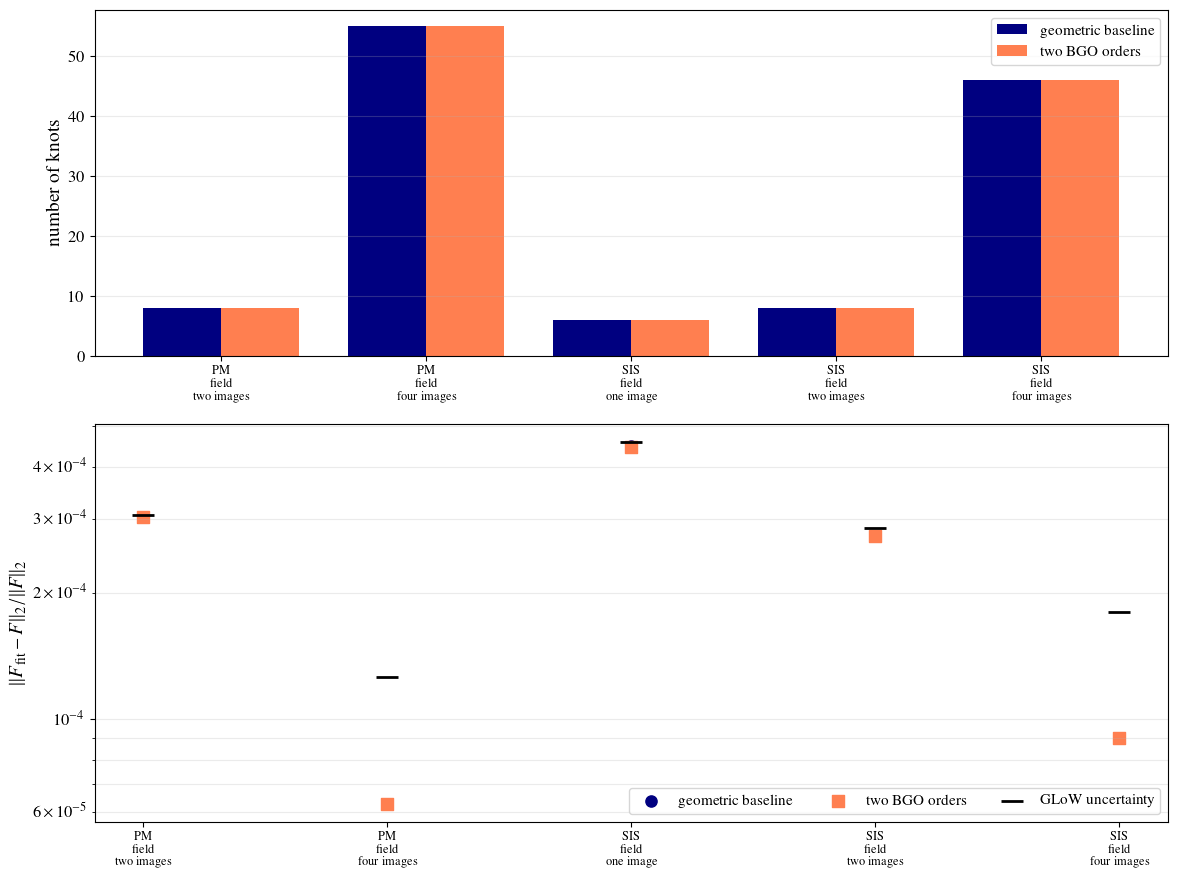

In [6]:

labels = [case['name'].replace(' / ', '\n').replace(', ', '\n') for case in cases]
geo_knots = [len(case['geometric_fit'].knots) for case in cases]
bgo_knots = [len(case['bgo_fit'].knots) for case in cases]
x = np.arange(len(cases))

fig, axes = plt.subplots(2, 1, figsize=(12, 9), gridspec_kw={'height_ratios': [1, 1.15]})
width = 0.38
axes[0].bar(x-width/2, geo_knots, width, label='geometric baseline')
axes[0].bar(x+width/2, bgo_knots, width, label='two BGO orders')
axes[0].set_ylabel('number of knots')
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, fontsize=9)
axes[0].legend()
axes[0].grid(axis='y', alpha=.25)

for j, case in enumerate(cases):
    for label, fit, marker in [('geometric baseline', case['geometric_fit'], 'o'),
                               ('two BGO orders', case['bgo_fit'], 's')]:
        axes[1].scatter(j, fit.relative_l2, marker=marker, s=65,
                        color='navy' if label.startswith('geometric') else 'coral',
                        label=label if j == 0 else None)
    axes[1].scatter(j, case['glow']['relative_l2_uncertainty'], marker='_', s=260,
                    color='black', label='GLoW uncertainty' if j == 0 else None)
axes[1].set_yscale('log')
axes[1].set_ylabel(r'$\|F_{\rm fit}-F\|_2/\|F\|_2$')
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, fontsize=9)
axes[1].grid(axis='y', which='both', alpha=.25)
axes[1].legend(ncol=3)
fig.tight_layout()
summary_path = FIGURE_DIR/'knot_and_error_summary.jpg'
fig.savefig(summary_path, dpi=200)
plt.show()



## Full-wave curves and residuals

For each regime, the panels show the complex trajectory, the residual trajectory,
amplitude, phase, and their pointwise errors.  Phase errors are wrapped to
$[-\pi,\pi]$.  The grey curve in the amplitude-error panel is the independent
GLoW resolution spread when it is nonzero.


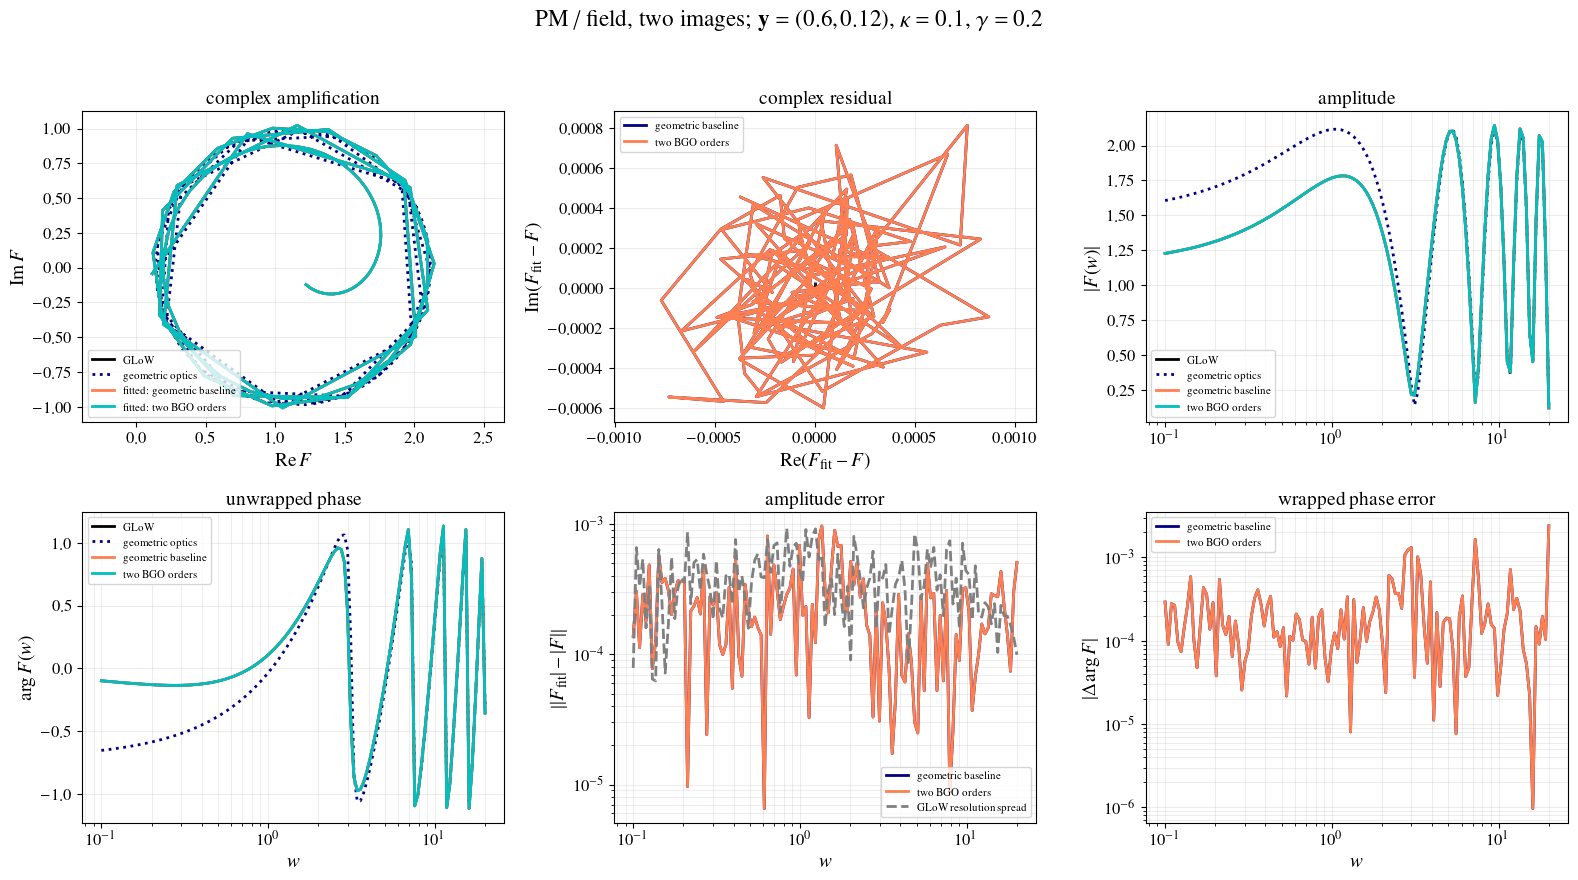

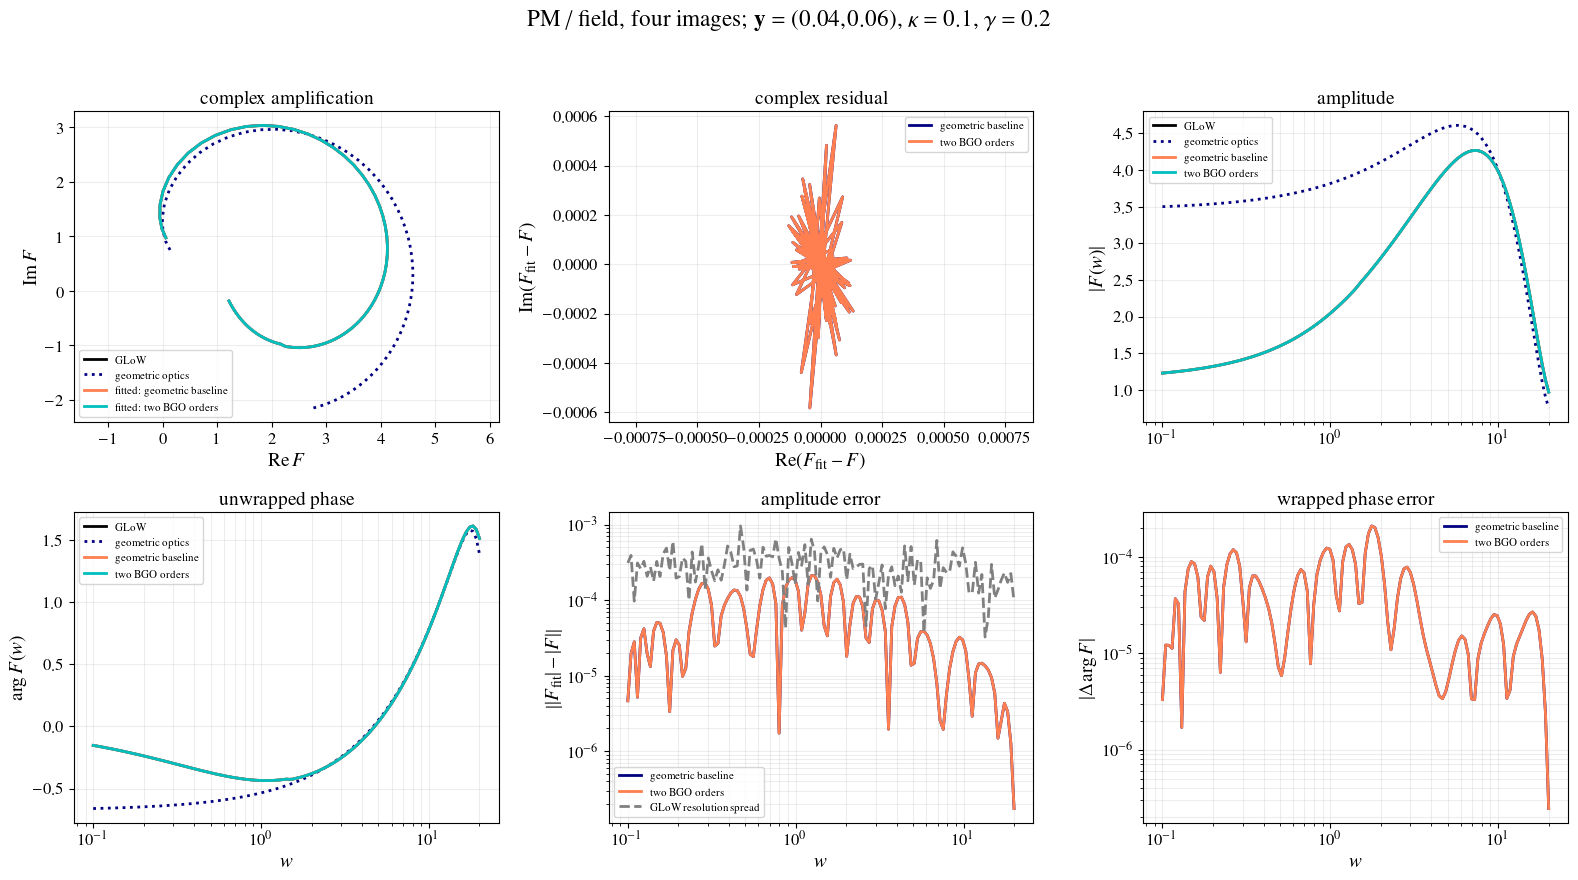

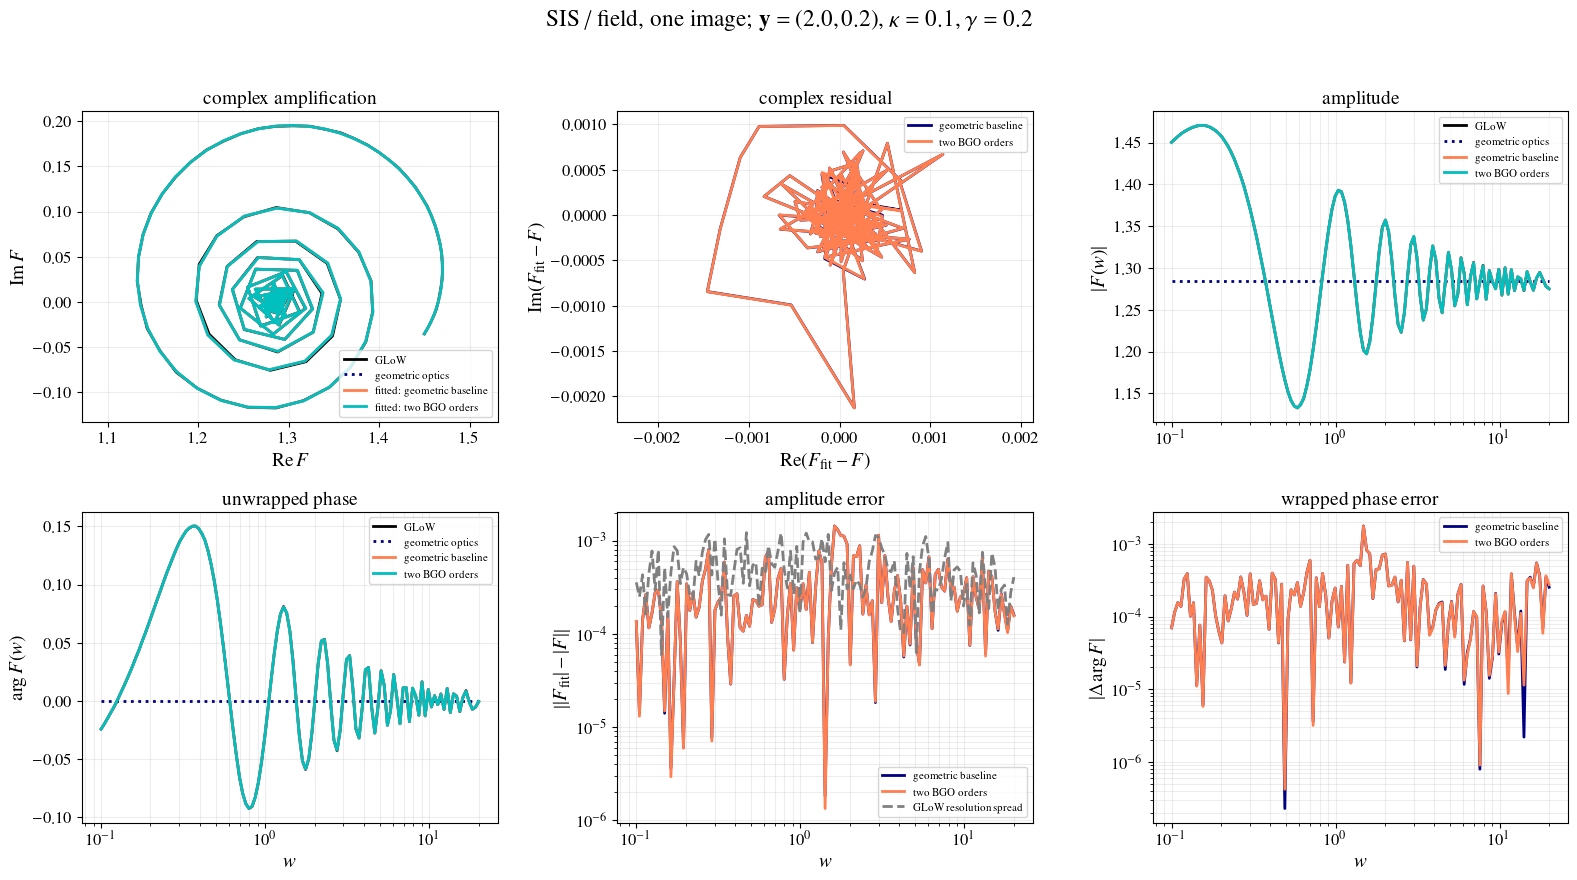

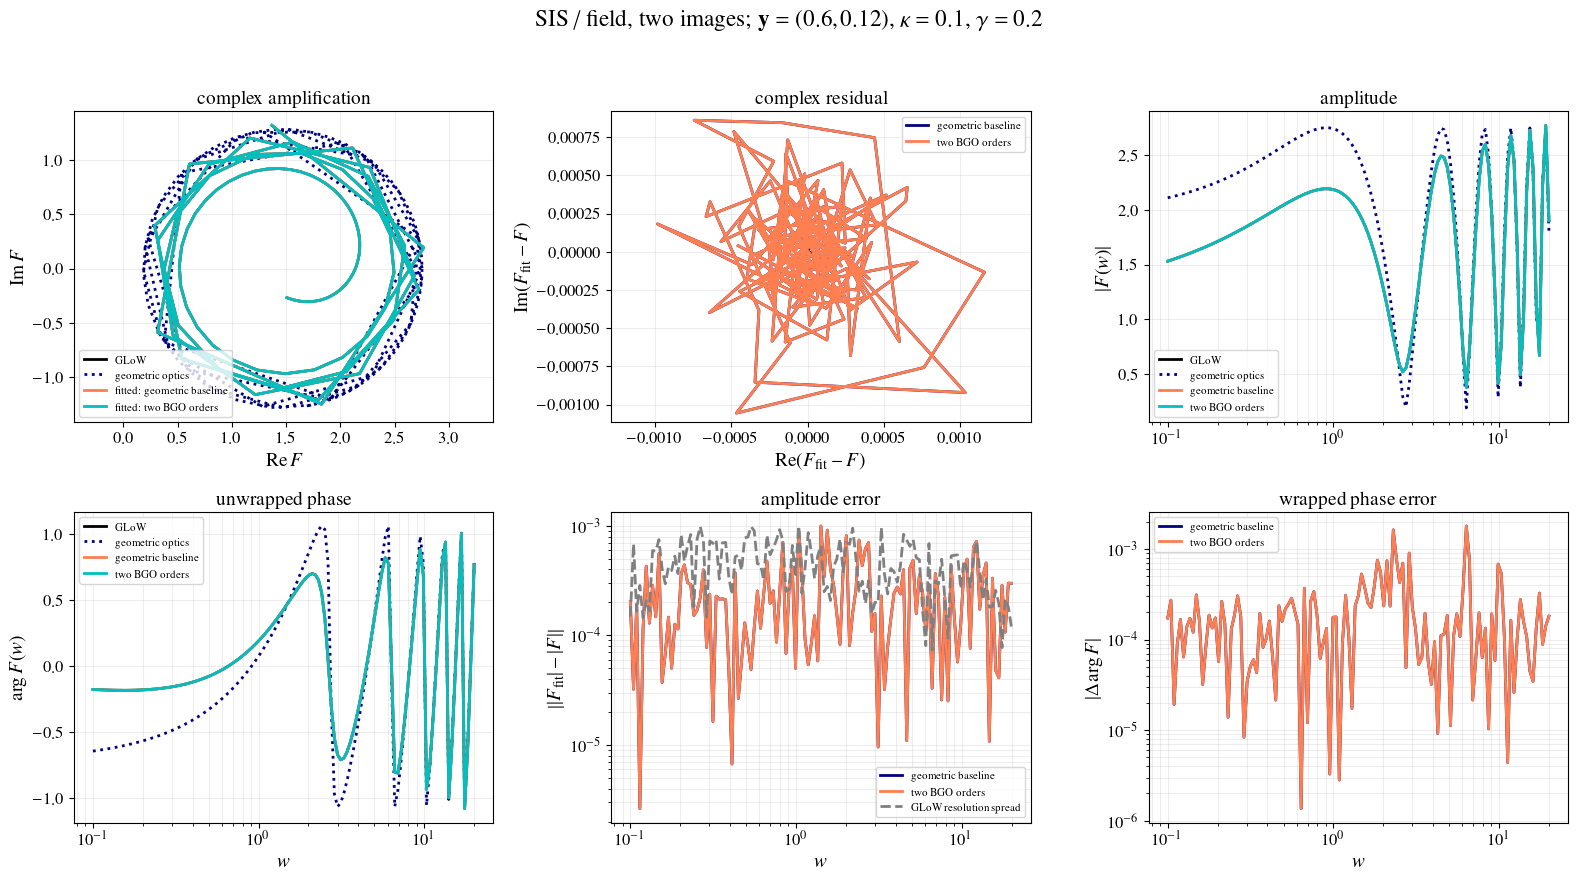

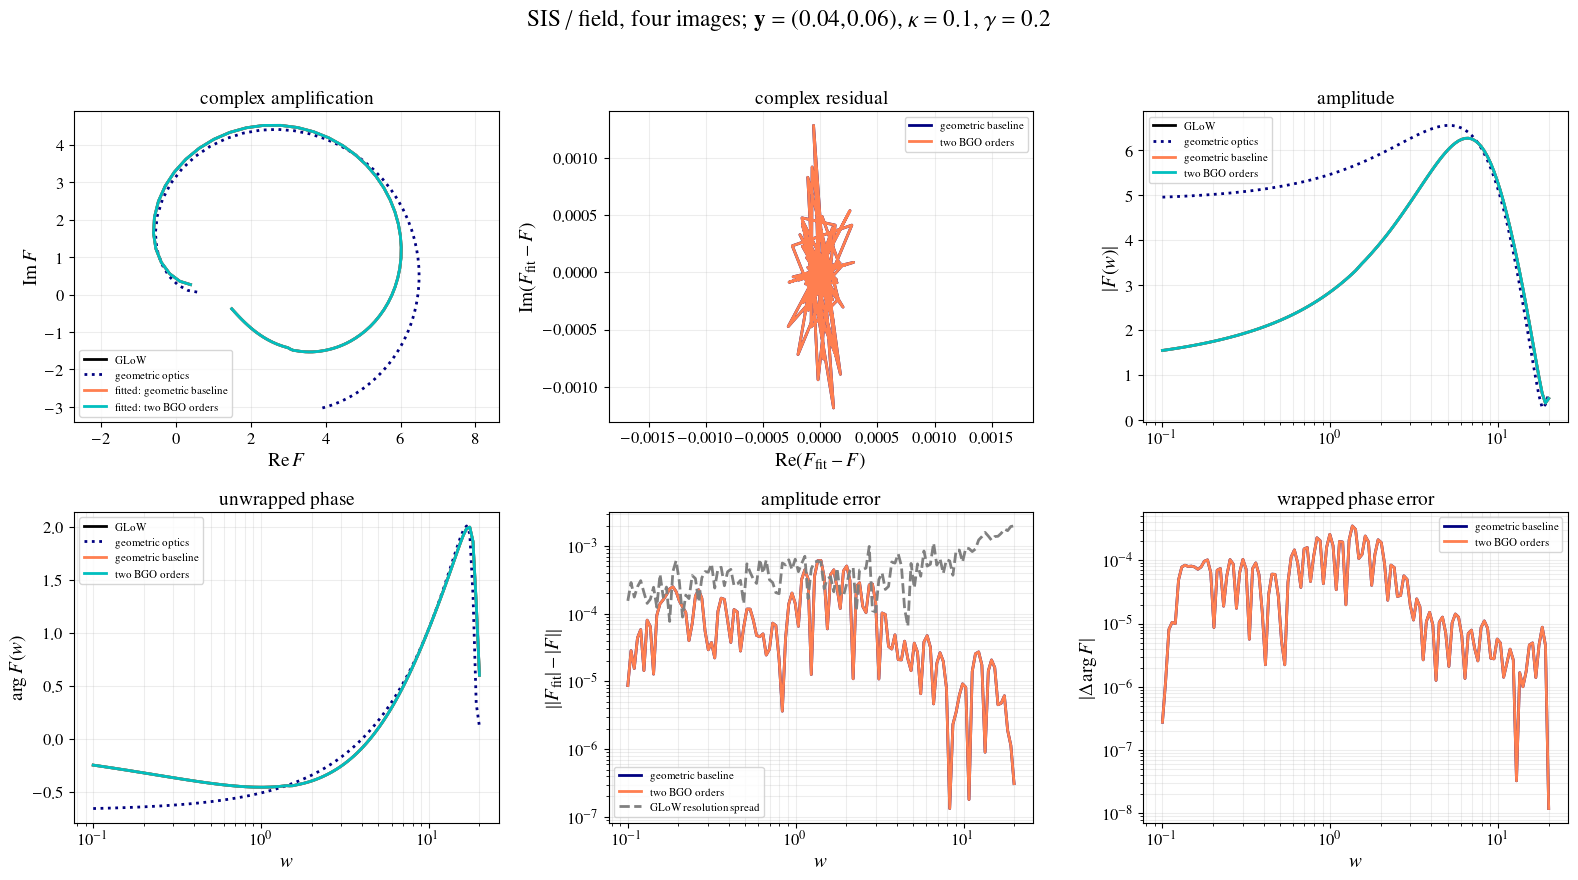

In [7]:

def wrapped_phase_error(prediction, truth):
    return np.angle(np.exp(1j*(np.angle(prediction)-np.angle(truth))))

for case in cases:
    w, truth, geo = case['w'], case['wave'], case['geometric']
    fitted_geo = case['geometric_fit'].amplification(w)
    fitted_bgo = case['bgo_fit'].amplification(w)
    spread = case['spread']

    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    axes[0, 0].plot(truth.real, truth.imag, color='black', label='GLoW')
    axes[0, 0].plot(geo.real, geo.imag, linestyle=':', label='geometric optics')
    axes[0, 0].plot(fitted_geo.real, fitted_geo.imag, label='fitted: geometric baseline')
    axes[0, 0].plot(fitted_bgo.real, fitted_bgo.imag, label='fitted: two BGO orders')
    axes[0, 0].set_xlabel(r'$\mathrm{Re}\,F$')
    axes[0, 0].set_ylabel(r'$\mathrm{Im}\,F$')
    axes[0, 0].set_title('complex amplification')
    axes[0, 0].axis('equal')

    residual_geo = fitted_geo-truth
    residual_bgo = fitted_bgo-truth
    axes[0, 1].plot(residual_geo.real, residual_geo.imag, label='geometric baseline')
    axes[0, 1].plot(residual_bgo.real, residual_bgo.imag, label='two BGO orders')
    axes[0, 1].scatter([0], [0], color='black', marker='+', s=80)
    axes[0, 1].set_xlabel(r'$\mathrm{Re}(F_{\rm fit}-F)$')
    axes[0, 1].set_ylabel(r'$\mathrm{Im}(F_{\rm fit}-F)$')
    axes[0, 1].set_title('complex residual')
    axes[0, 1].axis('equal')

    axes[0, 2].semilogx(w, abs(truth), color='black', label='GLoW')
    axes[0, 2].semilogx(w, abs(geo), linestyle=':', label='geometric optics')
    axes[0, 2].semilogx(w, abs(fitted_geo), label='geometric baseline')
    axes[0, 2].semilogx(w, abs(fitted_bgo), label='two BGO orders')
    axes[0, 2].set_ylabel(r'$|F(w)|$')
    axes[0, 2].set_title('amplitude')

    axes[1, 0].semilogx(w, np.unwrap(np.angle(truth)), color='black', label='GLoW')
    axes[1, 0].semilogx(w, np.unwrap(np.angle(geo)), linestyle=':', label='geometric optics')
    axes[1, 0].semilogx(w, np.unwrap(np.angle(fitted_geo)), label='geometric baseline')
    axes[1, 0].semilogx(w, np.unwrap(np.angle(fitted_bgo)), label='two BGO orders')
    axes[1, 0].set_xlabel(r'$w$')
    axes[1, 0].set_ylabel(r'$\arg F(w)$')
    axes[1, 0].set_title('unwrapped phase')

    floor = max(1e-12, 1e-8*np.max(abs(truth)))
    axes[1, 1].loglog(w, np.maximum(abs(abs(fitted_geo)-abs(truth)), floor),
                      label='geometric baseline')
    axes[1, 1].loglog(w, np.maximum(abs(abs(fitted_bgo)-abs(truth)), floor),
                      label='two BGO orders')
    if np.any(spread):
        axes[1, 1].loglog(w, np.maximum(spread, floor), color='gray',
                          linestyle='--', label='GLoW resolution spread')
    axes[1, 1].set_xlabel(r'$w$')
    axes[1, 1].set_ylabel(r'$\left||F_{\rm fit}|-|F|\right|$')
    axes[1, 1].set_title('amplitude error')

    phase_geo = abs(wrapped_phase_error(fitted_geo, truth))
    phase_bgo = abs(wrapped_phase_error(fitted_bgo, truth))
    axes[1, 2].loglog(w, np.maximum(phase_geo, 1e-12), label='geometric baseline')
    axes[1, 2].loglog(w, np.maximum(phase_bgo, 1e-12), label='two BGO orders')
    axes[1, 2].set_xlabel(r'$w$')
    axes[1, 2].set_ylabel(r'$|\Delta\arg F|$')
    axes[1, 2].set_title('wrapped phase error')

    title = (f"{case['name']}; $\\mathbf{{y}}={tuple(case['source'])}$, "
             f"$\\kappa={KAPPA}$, $\\gamma={GAMMA}$")
    fig.suptitle(title)
    for axis in axes.ravel():
        axis.grid(True, which='both', alpha=.22)
        axis.legend(fontsize=8)
    fig.tight_layout(rect=[0, 0, 1, .96])
    filename = case['name'].lower().replace(' / ', '_').replace(', ', '_').replace(' ', '_')+'.jpg'
    fig.savefig(FIGURE_DIR/filename, dpi=200)
    plt.show()



## Decomposed image functions in every regime

Each row below is one complete decomposition: the geometric baseline is above and
the two-order BGO baseline is below.  The crosses show the geometric endpoints
$\sqrt{|\mu_i|}$ in the complex plane.  Small circles mark the actual common
spline knots.  Thus the figures show both the visual smoothness of $G_i$ and how
many independent spline values were used to obtain it.


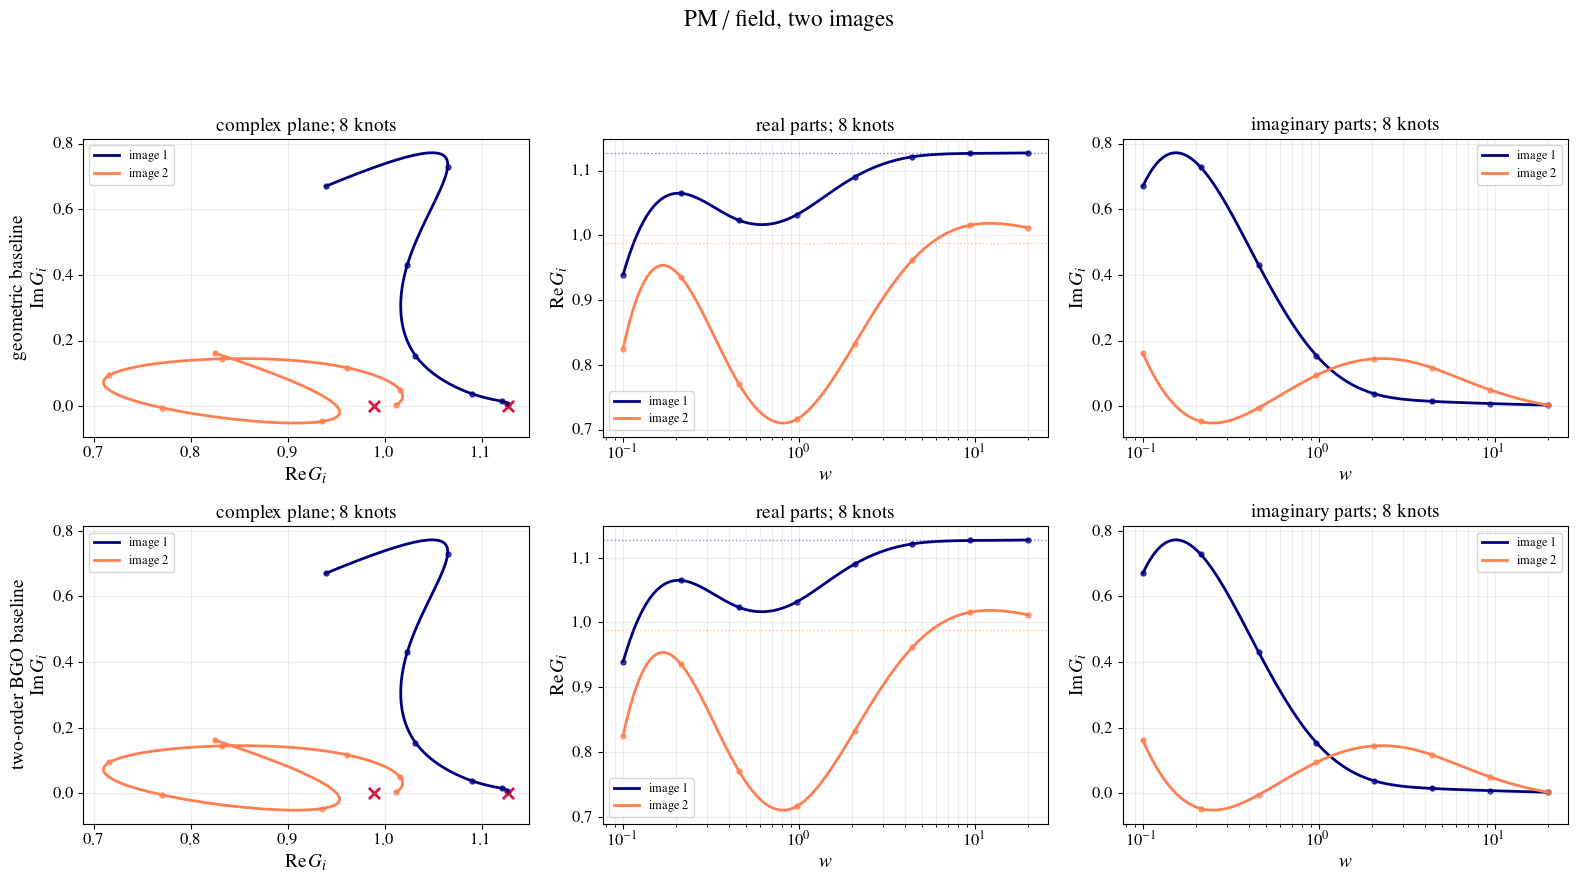

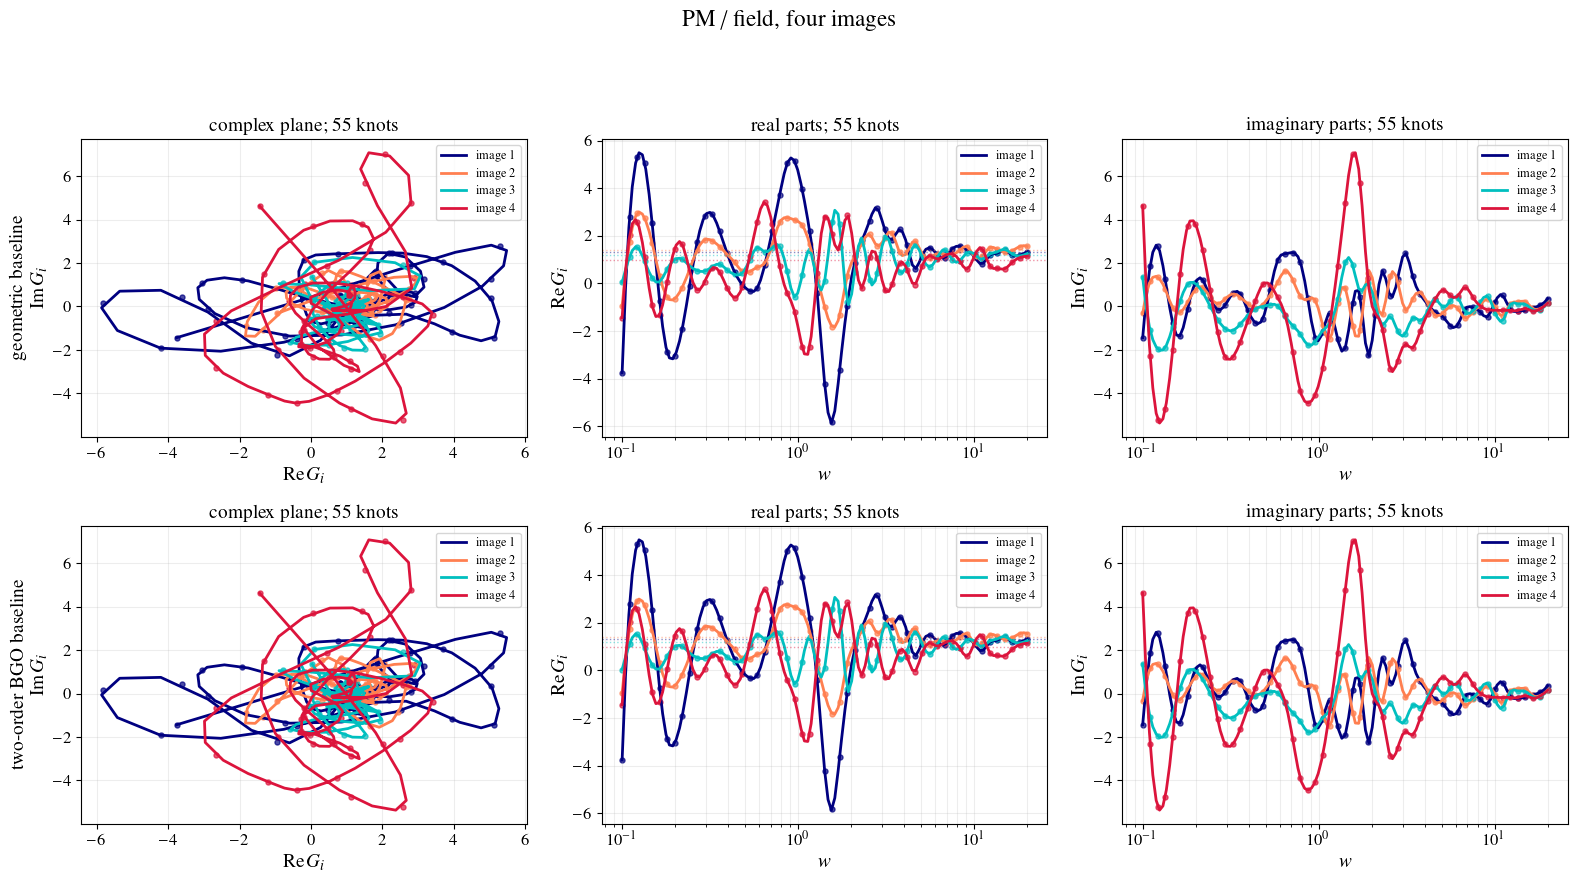

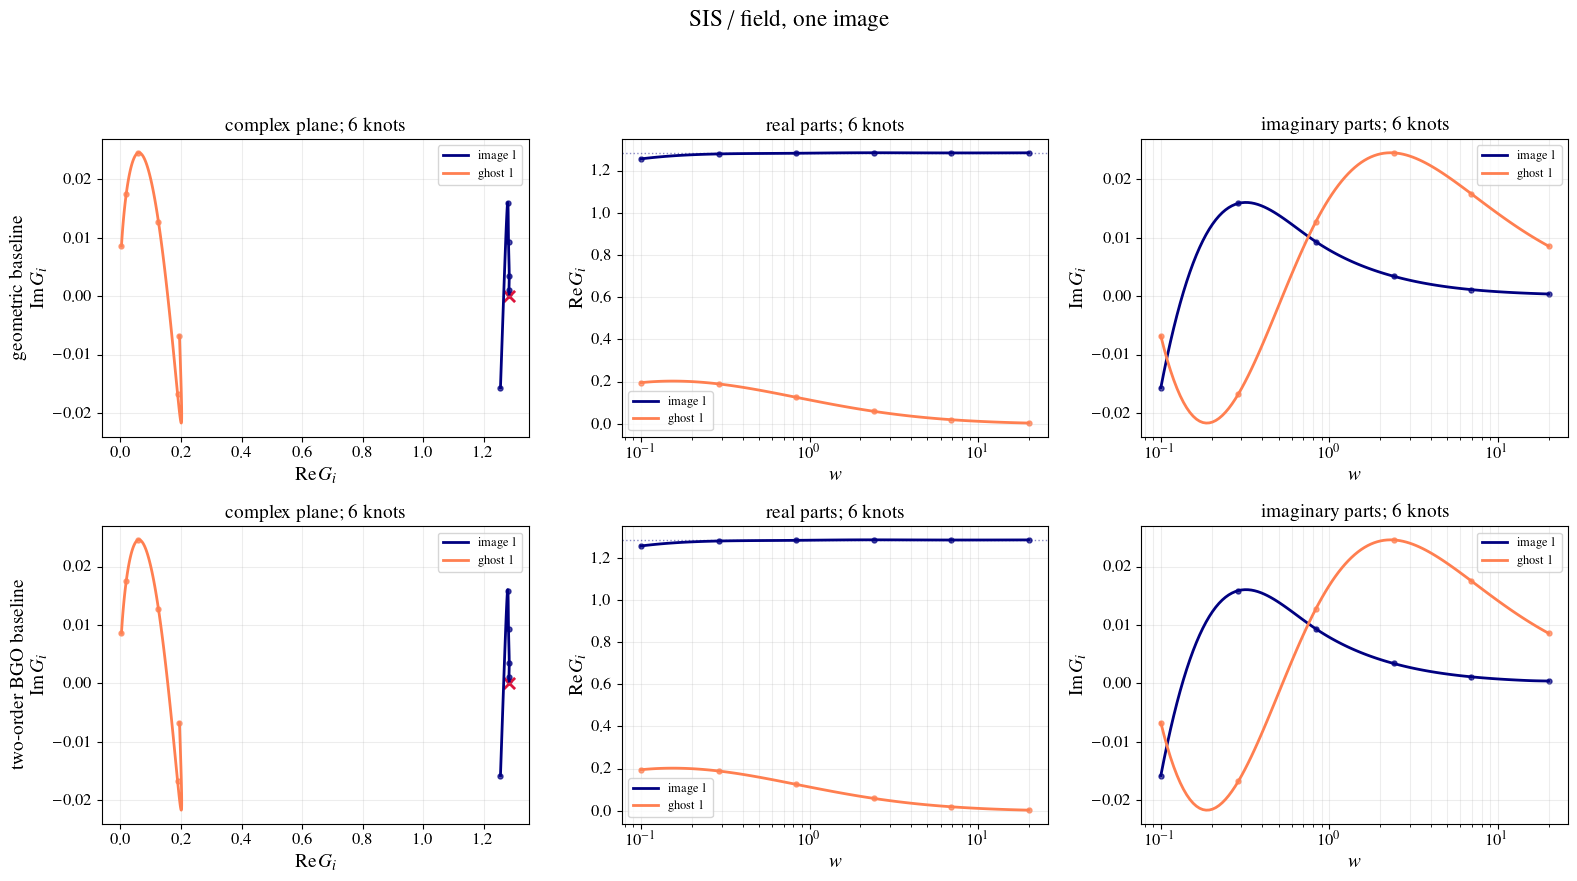

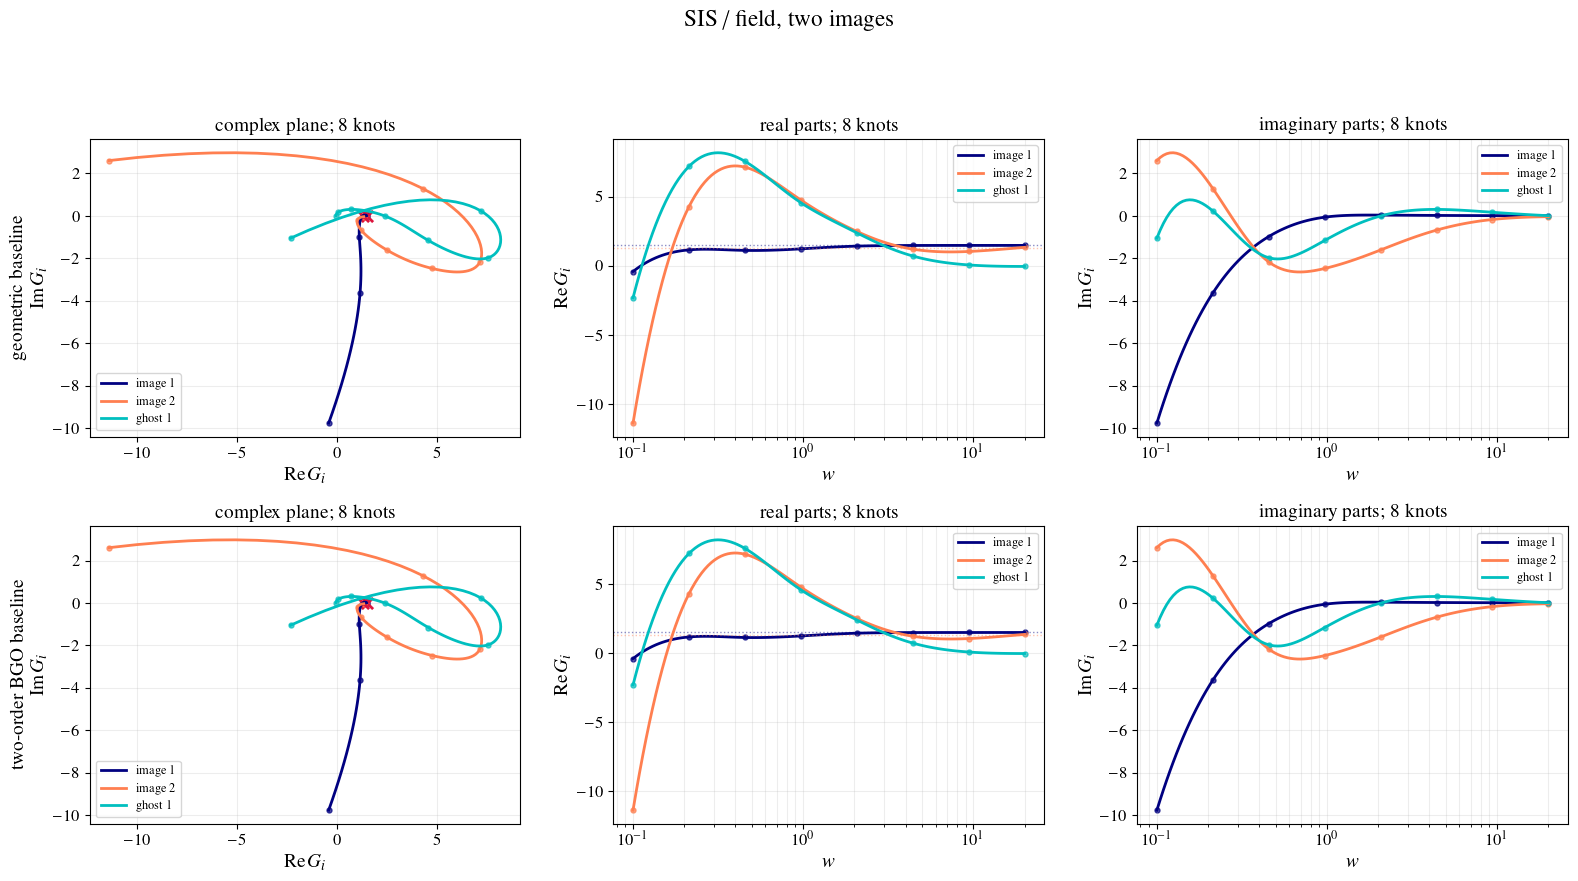

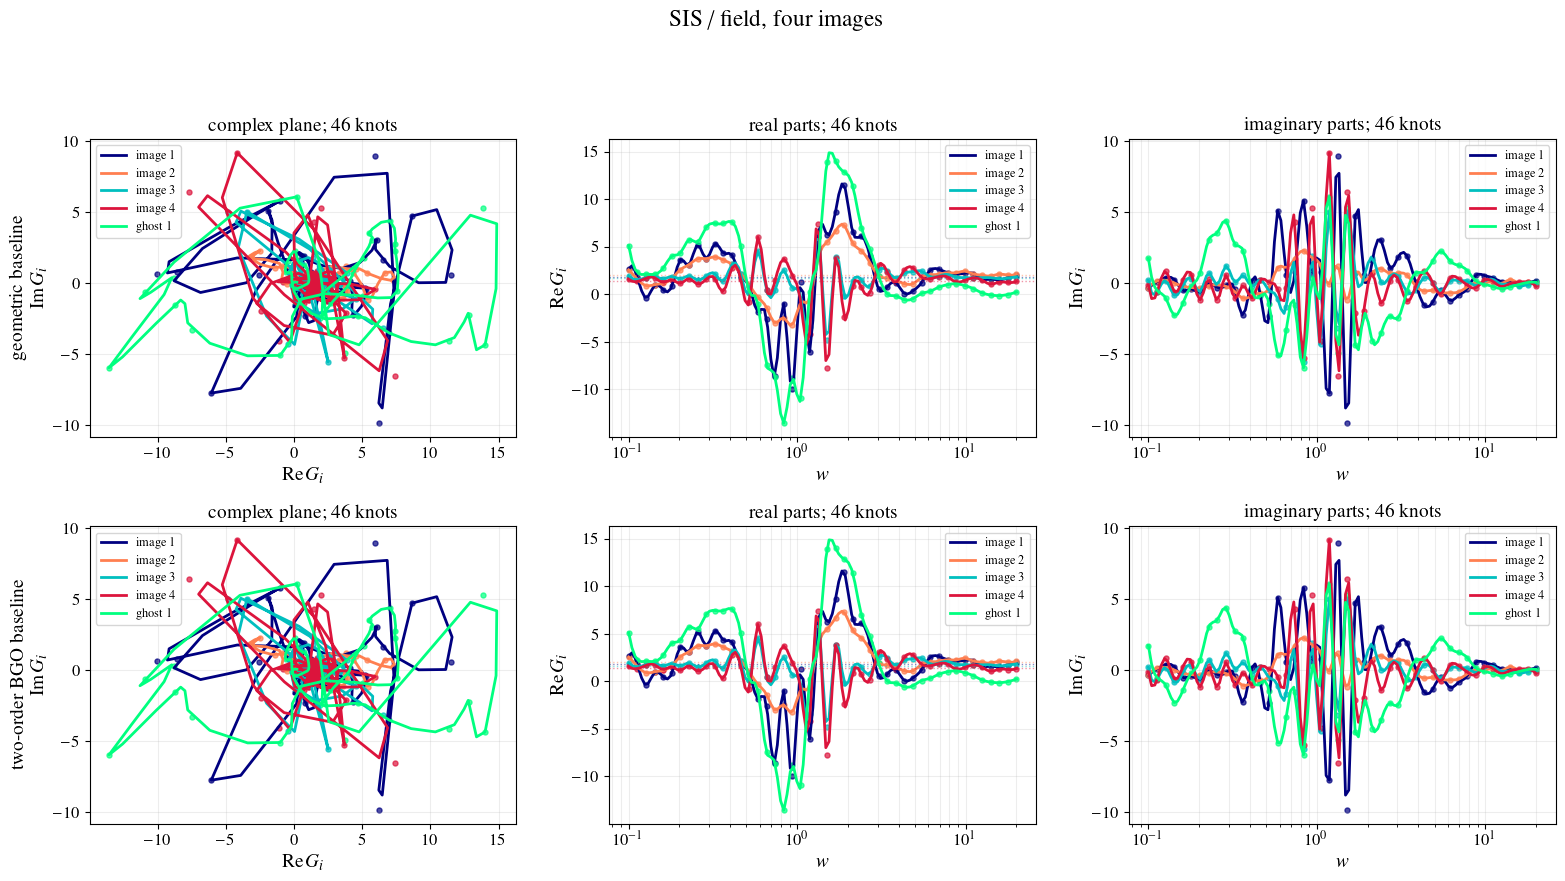

In [8]:

for case in cases:
    w = case['w']
    limits = np.sqrt(abs(case['magnifications']))
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    for row, (method, fit) in enumerate([
            ('geometric baseline', case['geometric_fit']),
            ('two-order BGO baseline', case['bgo_fit'])]):
        factors = fit.components(w)
        knot_w = 10**fit.knots
        knot_factors = fit.components(knot_w)
        for image_index, factor in enumerate(factors):
            physical = image_index < len(limits)
            label = f'image {image_index+1}' if physical else f'ghost {image_index-len(limits)+1}'
            color = my_colors[image_index]
            axes[row, 0].plot(factor.real, factor.imag, color=color, label=label)
            axes[row, 0].scatter(knot_factors[image_index].real,
                                 knot_factors[image_index].imag,
                                 color=color, s=13, alpha=.7)
            if physical:
                axes[row, 0].scatter(limits[image_index], 0, color='crimson',
                                     marker='x', s=65)
            axes[row, 1].semilogx(w, factor.real, color=color, label=label)
            axes[row, 1].scatter(knot_w, knot_factors[image_index].real,
                                 color=color, s=13, alpha=.7)
            if physical:
                axes[row, 1].axhline(limits[image_index], color=color,
                                     linestyle=':', linewidth=1, alpha=.45)
            axes[row, 2].semilogx(w, factor.imag, color=color, label=label)
            axes[row, 2].scatter(knot_w, knot_factors[image_index].imag,
                                 color=color, s=13, alpha=.7)
        axes[row, 0].set_ylabel(method+'\n'+r'$\mathrm{Im}\,G_i$')
        axes[row, 0].set_title(f'complex plane; {len(fit.knots)} knots')
        axes[row, 1].set_title(f'real parts; {len(fit.knots)} knots')
        axes[row, 2].set_title(f'imaginary parts; {len(fit.knots)} knots')
    for row in range(2):
        axes[row, 0].set_xlabel(r'$\mathrm{Re}\,G_i$')
        axes[row, 1].set_xlabel(r'$w$')
        axes[row, 1].set_ylabel(r'$\mathrm{Re}\,G_i$')
        axes[row, 2].set_xlabel(r'$w$')
        axes[row, 2].set_ylabel(r'$\mathrm{Im}\,G_i$')
    for axis in axes.ravel():
        axis.grid(True, which='both', alpha=.22)
        axis.legend(fontsize=9)
    fig.suptitle(case['name'])
    fig.tight_layout(rect=[0, 0, 1, .93])
    filename = case['name'].lower().replace(' / ', '_').replace(', ', '_').replace(' ', '_')+'_factors.jpg'
    fig.savefig(FIGURE_DIR/filename, dpi=200)
    plt.show()



## Why a visually smooth curve can require many knots

The plotted curve is $G_i$, while the spline parameters describe the rescaled
deviation

$$S_i(w)=(1+w)\,[G_i(w)-G_i^{\rm base}(w)].$$

A small high-frequency feature in $G_i$ is magnified by $1+w$ in the actual
spline.  It can therefore be nearly invisible on the scale of the complex-plane
plot while still needing several knots at a $10^{-4}$-level error target.

The SIS amplification also contains diffraction from the conical centre with a
delay different from the ordinary images.  A fitted ghost gives this component
its own phase.  The four-image calculations test one further candidate so that
an additional coherent residual can acquire its own fitted delay and phase when
the Fourier evidence supports it.
Near-degenerate phases can permit strongly cancelling factors in multi-image
fits.  The factor-scale condition rejects those solutions before accepting a
knot count.

All knots are uniformly spaced in $\log_{10}w$.  The adaptive procedure changes
only their integer count.  When that count changes, it evaluates the preceding
cubic splines at the new uniform knot positions to form the next initial curve.
There is therefore no knot-location search and no local concentration of knots.
These tests use the analytic ridge refit and require
$\max_i|G_i|\leq10\max_i\sqrt{|\mu_i|}$, so a formally accurate but strongly
cancelling SIS decomposition causes the uniform knot count to increase rather
than being accepted.


In [9]:

geo_better = sum(len(case['geometric_fit'].knots) < len(case['bgo_fit'].knots) for case in cases)
bgo_better = sum(len(case['bgo_fit'].knots) < len(case['geometric_fit'].knots) for case in cases)
equal = len(cases)-geo_better-bgo_better
worst = max(max(case['geometric_fit'].relative_l2, case['bgo_fit'].relative_l2) for case in cases)
total_seconds = sum(row['seconds'] for row in results)
display(Markdown(
    '## Numerical conclusion\n\n'
    f'All {2*len(cases)} adaptive fits satisfy the requested relative $L^2$ limit. '
    f'The largest attained value is ${worst:.3e}$.  At the measured limits, the two-order BGO '
    f'baseline uses fewer knots in {bgo_better} regimes, the geometric baseline uses fewer '
    f'in {geo_better}, and they tie in {equal}.  The decompositions took '
    f'${total_seconds:.2f}\,\mathrm{{s}}$ in total on this run.  The individual curves and the GLoW numerical '
    'spread above give the scale on which these fitted residuals are meaningful.'
))


## Numerical conclusion

All 10 adaptive fits satisfy the requested relative $L^2$ limit. The largest attained value is $4.474e-04$.  At the measured limits, the two-order BGO baseline uses fewer knots in 0 regimes, the geometric baseline uses fewer in 0, and they tie in 5.  The decompositions took $3.42\,\mathrm{s}$ in total on this run.  The individual curves and the GLoW numerical spread above give the scale on which these fitted residuals are meaningful.


## Complete calculation flow

For a feasible uniform knot set, a ridge-regularized solution supplies a stable
point strictly inside the allowed error ball.  This report uses that analytic
solution directly.  The general code can optionally run SLSQP once at the
selected final knot count.

```mermaid
flowchart TD
    A[Input w, F, image delays, magnifications, Morse phases] --> B{BGO coefficients supplied?}
    B -- yes --> C[Choose high-frequency BGO turn-on from known F]
    B -- no --> D[Use geometric image baselines]
    C --> E[Subtract supplied image baseline]
    D --> E
    E --> F{User requested k ghosts?}
    F -- yes --> G[Make a cheap 1 percent fit with physical images only]
    G --> G2[Fourier transform its rescaled residual and every rescaled image contribution]
    G2 --> G3[Choose up to k separated non-image peaks that pass a Fourier support threshold]
    G3 --> G4[Solve accepted ghost phases and magnitudes together by linear least squares]
    F -- no --> H[Build complete baseline]
    G4 --> H
    H --> I[Count strict local maxima of abs F and abs baseline]
    I --> J[Choose initial knot count from peak heuristic and user limits]
    J --> K[Build common cubic-spline basis for every image and ghost]
    K --> L[Compute minimum possible fixed-knot L2 error by linear least squares]
    L --> M{Meets GLoW uncertainty and factor-scale limit?}
    M -- no --> N[Increase the knot count by one]
    N --> O{Below maximum knot count?}
    O -- yes --> P[Build the new uniform grid and evaluate the previous splines on it]
    P --> K
    O -- no --> Q[Raise: requested accuracy is unattainable]
    M -- yes --> R[Find the strongest ridge-regularized feasible curve analytically]
    R --> R2{Iterative smoothness improvement requested?}
    R2 -- yes --> S[Run SLSQP once at the selected knot count]
    S --> T[Keep the lowest-cost feasible iterate, starting with the ridge curve]
    R2 -- no --> T
    T --> V{More than the minimum number of knots?}
    V -- no --> W[Return decomposition, timings and fit history]
    V -- yes --> X[Decrease knot count by one and build the new uniform grid]
    X --> Y[Evaluate current splines on the new grid and refit]
    Y --> Z{Reduced fit still meets the limit?}
    Z -- yes --> V
    Z -- no --> W
```
